# Single-instance Schrödinger PDE discovery

1. Construct the true PDE and one observed dataset, then visualize them.
2. Choose observed values $U$ or a pilot function $\widehat u$, including the split and integration locations.
3. Choose the dictionary and test functions for the weak form.
4. Choose the estimator and its tuning parameters.
5. Apply those choices to construct the weak system and run one method.
6. Compare the estimated coefficients with the true coefficients and visualize the results.

In [21]:
# Imports and display helpers
from pathlib import Path
from functools import partial
from time import perf_counter
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Latex

# This notebook lives in the repo root; ancestor search also supports notebooks/.
REPO = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / 'data_generation' / 'schrodinger.py').is_file()
     and (p / 'estimators' / 'loh_wainwright.py').is_file()),
    None,
)
if REPO is None:
    raise RuntimeError('Start Jupyter from the repository directory, then rerun this cell.')
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

from data_generation import Schrodinger
from estimators import CoCoLasso, LohWainwright, WSINDy
from weak_form import Equation, TestFunctions, WeakForm, library, spectral_test_functions
from pilot import perturbed_truth


def monomial_text(powers):
    return ' '.join(name if p == 1 else f'{name}^{p}'
                    for name, p in zip(('u', 'v'), powers) if p) or '1'


def term_text(term):
    base = monomial_text(term.powers)
    dx, dt = term.derivative
    ops = [f'd_{axis}' + (f'^{order}' if order > 1 else '')
           for axis, order in zip(('x', 't'), (dx, dt)) if order]
    return f'{" ".join(ops)}({base})' if ops else base


def term_latex(term):
    base = r'\,'.join(name if p == 1 else rf'{name}^{{{p}}}'
                      for name, p in zip(('u', 'v'), term.powers) if p) or '1'
    dx, dt = term.derivative
    total = dx + dt
    if total == 0:
        return base
    denominator = r'\,'.join(rf'\partial {axis}' + (rf'^{{{order}}}' if order > 1 else '')
                              for axis, order in zip(('x', 't'), (dx, dt)) if order)
    numerator = r'\partial' + (rf'^{{{total}}}' if total > 1 else '')
    return rf'\frac{{{numerator}}}{{{denominator}}}\left({base}\right)'


def show_equation(lhs, terms, beta, title, limit=None):
    selected = np.flatnonzero(beta != 0)
    order = selected[np.argsort(-np.abs(beta[selected]))]
    shown = order if limit is None else order[:limit]
    display(Markdown(f'**{title}**'))
    if len(shown) < len(selected):
        print(f'Showing {len(shown)} largest coefficients out of {len(selected)} nonzero terms; '
              'all coefficients are retained in coefficient_tables.')
    pieces = []
    for i in shown:
        sign = '-' if beta[i] < 0 else '+'
        pieces.append(f'{sign} {abs(beta[i]):.5g}' + r'\,' + term_latex(terms[i]))
    if not pieces:
        display(Latex(rf'\displaystyle {term_latex(lhs)} = 0'))
        return
    lines = []
    for start in range(0, len(pieces), 3):
        chunk = ' '.join(pieces[start:start + 3])
        if start == 0:
            chunk = chunk.removeprefix('+ ')
            lines.append(term_latex(lhs) + ' &= ' + chunk)
        else:
            lines.append(r'&\quad ' + chunk)
    display(Latex(r'\begin{aligned}' + r' \\ '.join(lines) + r'\end{aligned}'))

## 1. Construct the true PDE and the observed dataset

First choose the PDE coefficients, domain, sample size, noise level, and seed.
The two real-valued equations use $\psi=u-iv$:

$$u_t=a v_{xx}+b u^2v+b v^3,\qquad
v_t=-a u_{xx}-b u^3-b uv^2.$$

Observation noise has standard deviation $\sigma_c=\rho\,\mathrm{RMS}(u_{*c})$.
The display grid below is used only to visualize the true solution; it does not determine the random observations.

In [116]:
# PDE and observation settings
A, B = 0.5, 1.0
DOMAIN = ((-5.0, 5.0), (0.0, np.pi))
SAMPLING = 'random'                      # 'random' or 'grid'
N = 100                                # used for random sampling
GRID_SHAPE = (256, 251)                  # used for grid sampling
RHO = 0.1                               # noise sd / reference solution RMS
SEED = 1000
DISPLAY_GRID_SHAPE = (240, 180)          # visualization only

if SAMPLING not in {'random', 'grid'}:
    raise ValueError('SAMPLING must be random or grid.')
if RHO < 0 or not np.isfinite(RHO):
    raise ValueError('RHO must be finite and nonnegative.')
if SAMPLING == 'random' and (int(N) != N or N < 2):
    raise ValueError('N must be an integer of at least 2.')
if SAMPLING == 'grid' and (len(GRID_SHAPE) != 2 or min(GRID_SHAPE) < 2):
    raise ValueError('GRID_SHAPE must have two axis lengths of at least 2.')

pde = Schrodinger(a=A, b=B, domain=DOMAIN)
data = pde.random(N, rho=RHO, seed=SEED) if SAMPLING == 'random' else pde.grid(GRID_SHAPE, rho=RHO, seed=SEED)

for q, (equation, beta) in enumerate(zip(pde.equations, pde.beta_star)):
    show_equation(equation.lhs, equation.rhs, beta, f'True equation {q}')
display(pd.DataFrame({
    'component': ['u', 'v'],
    'observations': [data.U[0].size] * 2,
    'noise sd': data.sigma,
    'observed RMS': np.sqrt(np.mean(data.U.reshape(2, -1)**2, axis=1)),
}))
print(f'Sampling: {SAMPLING}; seed: {SEED}; U.shape: {data.U.shape}; domain: {data.domain}')

**True equation 0**

<IPython.core.display.Latex object>

**True equation 1**

<IPython.core.display.Latex object>

,component,observations,noise sd,observed RMS
0,u,100,0.063243,0.662559
1,v,100,0.063243,0.615683


Sampling: random; seed: 1000; U.shape: (2, 100); domain: ((-5.0, 5.0), (0.0, 3.141592653589793))


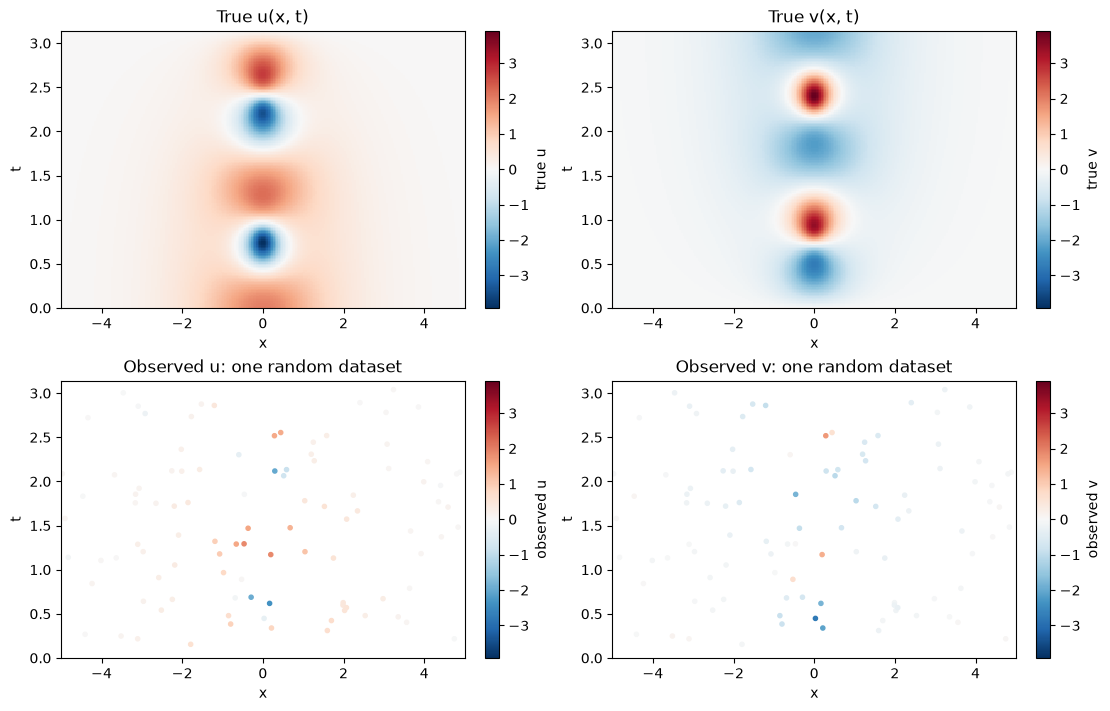

In [118]:
# Inspect the true solution and observations before choosing a method
display_x = np.linspace(*DOMAIN[0], DISPLAY_GRID_SHAPE[0])
display_t = np.linspace(*DOMAIN[1], DISPLAY_GRID_SHAPE[1])
xx, tt = np.meshgrid(display_x, display_t, indexing='ij')
true_fields = pde.solution(xx, tt)
observed_x, observed_t = [z.ravel() for z in data.points]

fig, axes = plt.subplots(2, 2, figsize=(11, 7), constrained_layout=True)
for c, name in enumerate(('u', 'v')):
    limit = max(np.max(np.abs(true_fields[c])), np.max(np.abs(data.U[c])), 1e-12)
    image = axes[0, c].pcolormesh(display_x, display_t, true_fields[c].T,
                                 shading='auto', cmap='RdBu_r', vmin=-limit, vmax=limit)
    dots = axes[1, c].scatter(observed_x, observed_t, c=data.U[c].ravel(), s=9,
                              cmap='RdBu_r', vmin=-limit, vmax=limit, rasterized=True)
    fig.colorbar(image, ax=axes[0, c], label=f'true {name}')
    fig.colorbar(dots, ax=axes[1, c], label=f'observed {name}')
    axes[0, c].set(title=f'True {name}(x, t)')
    axes[1, c].set(title=f'Observed {name}: one {SAMPLING} dataset')
    for ax in axes[:, c]:
        ax.set(xlabel='x', ylabel='t', xlim=DOMAIN[0], ylim=DOMAIN[1])
plt.show()

3d plot

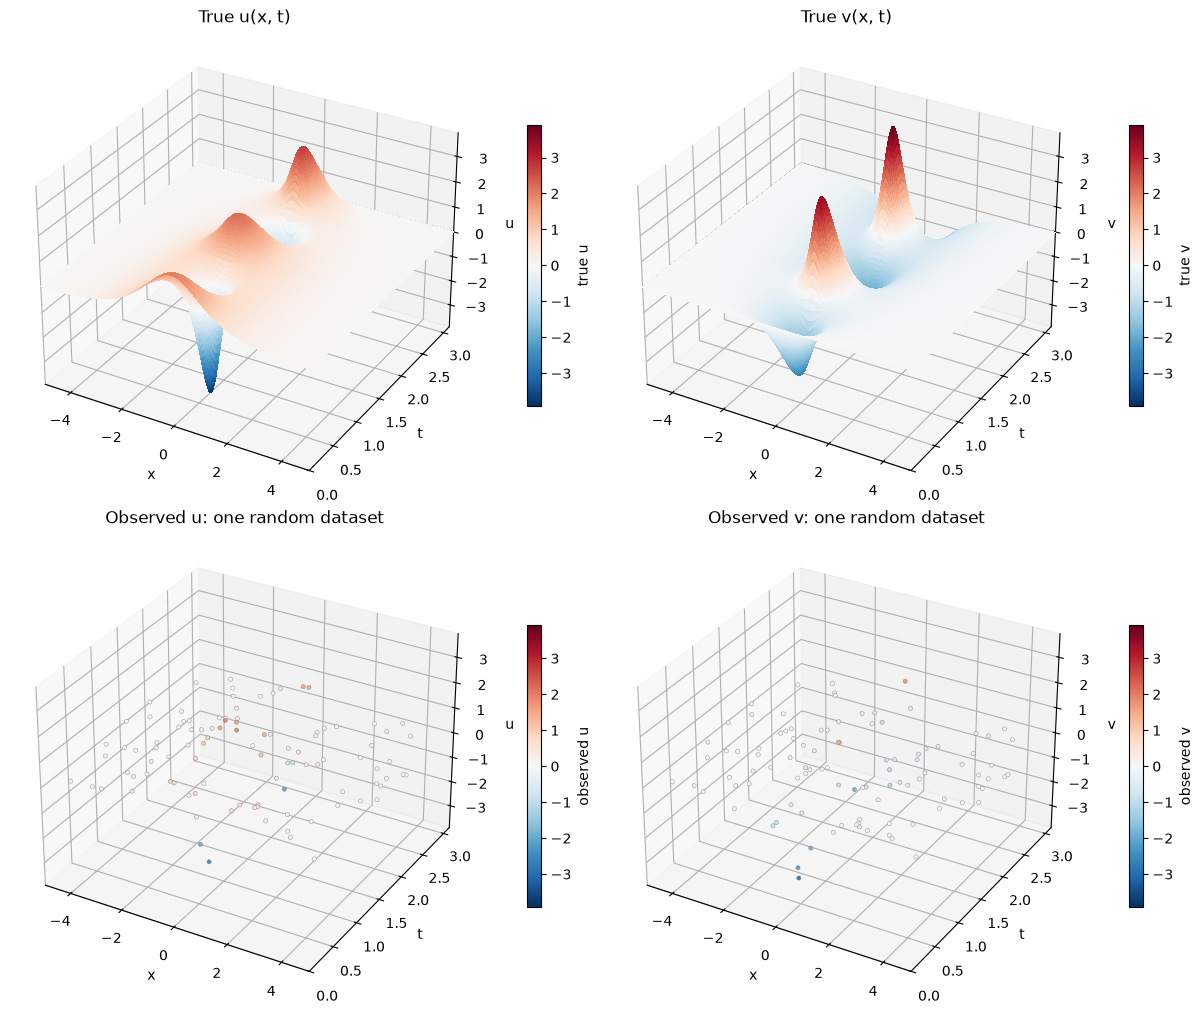

In [119]:
# Inspect the true solution and observations before choosing a method
display_x = np.linspace(*DOMAIN[0], DISPLAY_GRID_SHAPE[0])
display_t = np.linspace(*DOMAIN[1], DISPLAY_GRID_SHAPE[1])
xx, tt = np.meshgrid(display_x, display_t, indexing='ij')
true_fields = pde.solution(xx, tt)
observed_x, observed_t = [z.ravel() for z in data.points]

fig, axes = plt.subplots(2, 2, figsize=(12, 10), subplot_kw={'projection': '3d'}, constrained_layout=True)
for c, name in enumerate(('u', 'v')):
    limit = max(np.max(np.abs(true_fields[c])), np.max(np.abs(data.U[c])), 1e-12)
    surface = axes[0, c].plot_surface(xx, tt, true_fields[c], cmap='RdBu_r', vmin=-limit, vmax=limit,
                                      rcount=DISPLAY_GRID_SHAPE[0], ccount=DISPLAY_GRID_SHAPE[1],
                                      linewidth=0, antialiased=False)
    dots = axes[1, c].scatter(observed_x, observed_t, data.U[c].ravel(), c=data.U[c].ravel(), s=9,
                              cmap='RdBu_r', vmin=-limit, vmax=limit, depthshade=False,
                              edgecolors='0.5', linewidths=0.3)
    fig.colorbar(surface, ax=axes[0, c], shrink=0.6, pad=0.1, label=f'true {name}')
    fig.colorbar(dots, ax=axes[1, c], shrink=0.6, pad=0.1, label=f'observed {name}')
    axes[0, c].set(title=f'True {name}(x, t)')
    axes[1, c].set(title=f'Observed {name}: one {SAMPLING} dataset')
    for ax in axes[:, c]:
        ax.set(xlabel='x', ylabel='t', zlabel=name, xlim=DOMAIN[0], ylim=DOMAIN[1], zlim=(-limit, limit))
plt.show()

## 2. Choose the input: observed $U$ or pilot $\widehat u$

- `USE_PILOT=False`: use all observed values and their original locations.
- `USE_PILOT=True`: use `data.split()` to separate pilot and regression observations.
  Build $\widehat u$ from the pilot half. Evaluate it at fresh uniform Monte Carlo points,
  or at the regression half's locations when `USE_ORIGINAL_POINTS=True`.

The default `perturbed_truth` builder is a **simulated oracle pilot**: it perturbs the known true solution.
It is not fitted to the observations. Replace `PILOT_BUILDER` with a function
`pilot(data, seed) -> uhat`, where `uhat(x, t)` returns shape `(2, ...)`, to use another pilot.
For a random dataset the split uses separate halves of the observations; on a grid it uses alternating time slices.
This cell chooses the policy; splitting and pilot evaluation happen in the execution stage.

In [108]:
# Input and splitting policy only; no split or pilot evaluation happens here
USE_PILOT = True
PILOT_BUILDER = partial(
    perturbed_truth, pde=pde, zeta=1.0, gamma=1 / 3, modes=8,
)
MC_POINTS = None                         # None = regression-half size; only used for fresh pilot MC points
USE_ORIGINAL_POINTS = True              # True = evaluate the pilot at regression locations

print('Selected input:', 'pilot u-hat' if USE_PILOT else 'observed U')
if USE_PILOT:
    print('Split policy:', 'two point-sample halves' if SAMPLING == 'random' else 'alternating time slices')
    print('Integration locations:', 'regression locations' if USE_ORIGINAL_POINTS else 'fresh uniform MC points')
    if not USE_ORIGINAL_POINTS:
        print('Requested MC points:', 'regression-half size' if MC_POINTS is None else MC_POINTS)
else:
    print('All observations will be used; pilot-only settings are inactive.')

Selected input: pilot u-hat
Split policy: two point-sample halves
Integration locations: regression locations


## 3. Choose the weak form

Choose the RHS dictionary and the test-function family. The dictionary contains the constant and
$\partial_x^s(u^p v^q)$ for $0\leq s\leq\texttt{MAX\_DX}$ and
$1\leq p+q\leq\texttt{MAX\_POLY\_DEGREE}$. The LHS contains the known first time derivative.

Fixed test functions use the specified radii, exponents, and centers independently of the data.
The initial values reproduce the paper's test-function geometry on this domain.
For `spectral`, the repo constructs the family from the regression observations during execution.
This cell sets the choices; it does not construct a dictionary, test functions, or weak matrices.

In [109]:
# Dictionary settings
MAX_DX = 6                              # maximum spatial derivative order
MAX_POLY_DEGREE = 6                     # maximum total degree in (u, v)

# Test-function settings
TEST_FUNCTIONS = 'fixed'                # 'fixed' or 'spectral'
RADII = (19 * 10 / 256, 25 * np.pi / 250)
DEGREES = (11, 10)
CENTER_SPACING = (5 * 10 / 256, 5 * np.pi / 250)
CENTER_COUNTS = (20, 20)                # used when CENTER_SPACING is None

# Alternative fixed family: uncomment all four lines to try the proposed MC baseline.
# RADII = (2.0, np.pi / 5)
# DEGREES = (7, 2)
# CENTER_SPACING = None
# CENTER_COUNTS = (20, 20)

# Used only for spectral test functions, which require random observations.
SPECTRAL_WIDTH = 1.0
SPECTRAL_SPACING = 50
SPECTRAL_ALPHA = 0.1

SHOW_FULL_DICTIONARY = False
TABLE_ROWS = 25

display(pd.DataFrame({
    'choice': ['max spatial derivative', 'max polynomial degree', 'test-function family'],
    'value': [MAX_DX, MAX_POLY_DEGREE, TEST_FUNCTIONS],
}))
if TEST_FUNCTIONS == 'fixed':
    display(pd.DataFrame({
        'coordinate': ['x', 't'], 'radius': RADII, 'exponent': DEGREES,
        'center spacing / count': CENTER_COUNTS if CENTER_SPACING is None else CENTER_SPACING,
    }))

,choice,value
0,max spatial derivative,6
1,max polynomial degree,6
2,test-function family,fixed


,coordinate,radius,exponent,center spacing / count
0,x,0.742188,11,0.195312
1,t,0.314159,10,0.062832


## 4. Choose the estimation method

Choose one estimator and its tuning parameters. A scalar `LAM` fixes the penalty;
an array requests the repo's corrected cross-validation for LW or CoCoLasso.
The default `LAM=0.05` is an explicit demonstration setting, not an instance-tuned optimum.

LW and CoCoLasso use the repo's column RMS scaling. `LW_RADIUS` constrains the scaled coefficients for LW only.
The value 0.79 comes from the repo's oracle calibration for random n=1000 and the paper test functions;
it is not recalibrated when other settings change. MSTLS uses its own threshold grid.
The repo does not expose the selected CV penalty as a public result.
This cell selects the method; the estimator is instantiated and fitted in the execution stage.

In [110]:
# Estimator settings only; no estimator is created or fitted here
METHOD = 'lw'                         # 'coco', 'lw', 'mstls', or 'least_squares'

# LW / CoCoLasso
LAM = 0.05
# LAM = np.geomspace(0.005, 1.0, 18)     # corrected CV over the same grid as repo experiments
FOLDS = 5
LW_RADIUS = 0.79
SOLVER_TOL = 1e-10
SOLVER_MAX_ITER = 1_000_000

# MSTLS only
MSTLS_LAMBDAS = 10.0 ** np.linspace(-4, 0, 50)
SHOW_GRAM_DIAGNOSTICS = True

print('Selected method:', METHOD)
if METHOD in {'coco', 'lw'}:
    print('Penalty selection:', f'{FOLDS}-fold corrected CV' if np.ndim(LAM) else 'fixed lambda')
    print('Lambda/candidate grid:', np.atleast_1d(LAM))
    if METHOD == 'lw':
        print('Scaled l1 constraint radius:', LW_RADIUS)
elif METHOD == 'mstls':
    print('MSTLS threshold candidates:', len(MSTLS_LAMBDAS))

Selected method: lw
Penalty selection: fixed lambda
Lambda/candidate grid: [0.05]
Scaled l1 constraint radius: 0.79


## 5. Apply the choices and run the method

The decisions are now complete. Apply the input/split policy, construct the dictionary and test functions,
and assemble the weak systems $(X,Y)$. Then instantiate the selected estimator and call the existing
`estimator.estimate(wf, equation)` once for each of the two equations.

In [111]:
# 5a. Apply the selected input policy and construct the weak systems
if int(MAX_DX) != MAX_DX or MAX_DX < 0 or int(MAX_POLY_DEGREE) != MAX_POLY_DEGREE or MAX_POLY_DEGREE < 1:
    raise ValueError('Require integer MAX_DX >= 0 and MAX_POLY_DEGREE >= 1.')
if TEST_FUNCTIONS not in {'fixed', 'spectral'}:
    raise ValueError('TEST_FUNCTIONS must be fixed or spectral.')
if TEST_FUNCTIONS == 'spectral' and data.design != 'random':
    raise ValueError('The repo spectral constructor requires random observations.')
if USE_PILOT and not callable(PILOT_BUILDER):
    raise ValueError('PILOT_BUILDER must be callable when USE_PILOT=True.')
if USE_PILOT and MC_POINTS is not None and (int(MC_POINTS) != MC_POINTS or MC_POINTS < 2):
    raise ValueError('MC_POINTS must be None or an integer of at least 2.')

pilot_data, uhat = None, None
regression_data = data
if USE_PILOT:
    pilot_data, regression_data = data.split()
    if min(pilot_data.U[0].size, regression_data.U[0].size) < 2:
        raise ValueError('Each split must contain at least two observations.')
    if data.design == 'grid' and min(len(pilot_data.coords[-1]), len(regression_data.coords[-1])) < 2:
        raise ValueError('Grid splitting needs at least two time points in each half.')
    uhat = PILOT_BUILDER(pilot_data, seed=(SEED, 1))

rhs = library(tuple((s, 0) for s in range(MAX_DX + 1)), MAX_POLY_DEGREE, 2)
equations = [Equation(eq.lhs, rhs) for eq in pde.equations]

if TEST_FUNCTIONS == 'fixed':
    if len(RADII) != 2 or len(DEGREES) != 2:
        raise ValueError('RADII and DEGREES must have one entry for x and one for t.')
    required = (MAX_DX + 1, 2)
    if any(int(p) != p or p < r for p, r in zip(DEGREES, required)):
        raise ValueError(f'Fixed DEGREES must be integers >= {required} for this dictionary/LHS.')
    centers = []
    for a, ((lo, hi), radius) in enumerate(zip(DOMAIN, RADII)):
        if not 0 < radius < (hi - lo) / 2:
            raise ValueError('Each radius must be positive and smaller than half the domain length.')
        if CENTER_SPACING is None:
            count = int(CENTER_COUNTS[a])
            if count < 1 or count != CENTER_COUNTS[a]:
                raise ValueError('CENTER_COUNTS entries must be positive integers.')
            centers.append(np.linspace(lo + radius, hi - radius, count))
        else:
            spacing = CENTER_SPACING[a]
            if spacing <= 0:
                raise ValueError('CENTER_SPACING entries must be positive.')
            count = int(np.floor((hi - lo - 2 * radius) / spacing + 1e-10)) + 1
            centers.append(lo + radius + spacing * np.arange(count))
    test_functions = TestFunctions(tuple(centers), tuple(RADII), tuple(DEGREES))
else:
    test_functions = partial(spectral_test_functions, equations=equations, width=SPECTRAL_WIDTH,
                             spacing=SPECTRAL_SPACING, alpha=SPECTRAL_ALPHA)

wf = WeakForm(regression_data, test_functions, u=uhat, m=MC_POINTS,
              use_original_data=USE_ORIGINAL_POINTS, seed=(SEED, 2))
phi = wf.phi
K = int(np.prod([len(c) for c in phi.centers]))
systems = [wf.system(eq) for eq in equations]
if not all(np.all(np.isfinite(X)) and np.all(np.isfinite(Y)) for X, Y in systems):
    raise ValueError('The weak systems contain nonfinite values.')

print('Weak-form input:', 'pilot u-hat' if USE_PILOT else 'observed U')
if USE_PILOT:
    print(f'Pilot observations: {pilot_data.U[0].size}; regression observations: {regression_data.U[0].size}')
print(f'Integration design: {wf.data.design}; integration points: {wf.data.U[0].size}; K: {K}; P: {len(rhs)}')
display(pd.DataFrame({
    'coordinate': ['x', 't'], 'radius': phi.radii, 'exponent': phi.degrees,
    'centers': [len(c) for c in phi.centers],
}))
display(pd.DataFrame([
    {'equation': q, 'LHS': term_text(eq.lhs), 'X shape': X.shape, 'Y shape': Y.shape,
     'min column RMS': np.sqrt(np.mean(X**2, axis=0)).min(),
     'max column RMS': np.sqrt(np.mean(X**2, axis=0)).max()}
    for q, (eq, (X, Y)) in enumerate(zip(equations, systems))
]))
dictionary_table = pd.DataFrame({
    'column': np.arange(len(rhs)), 'term': [term_text(t) for t in rhs],
    'powers (u, v)': [t.powers for t in rhs], 'derivative (x, t)': [t.derivative for t in rhs],
})
display(dictionary_table if SHOW_FULL_DICTIONARY else dictionary_table.head(TABLE_ROWS))
if not SHOW_FULL_DICTIONARY:
    print(f'Dictionary preview: first {min(TABLE_ROWS, len(rhs))} of {len(rhs)} columns. '
          'Use dictionary_table for all columns.')

Weak-form input: pilot u-hat
Pilot observations: 2500; regression observations: 2500
Integration design: random; integration points: 2500; K: 1804; P: 190


,coordinate,radius,exponent,centers
0,x,0.742188,11,44
1,t,0.314159,10,41


,equation,LHS,X shape,Y shape,min column RMS,max column RMS
0,0,d_t(u),"(1804, 190)","(1804,)",0.043739,2.683143e+06
1,1,d_t(v),"(1804, 190)","(1804,)",0.043739,2.683143e+06


,column,term,"powers (u, v)","derivative (x, t)"
0,0,1,"(0, 0)","(0, 0)"
1,1,v,"(0, 1)","(0, 0)"
2,2,u,"(1, 0)","(0, 0)"
3,3,v^2,"(0, 2)","(0, 0)"
4,4,u v,"(1, 1)","(0, 0)"
5,5,u^2,"(2, 0)","(0, 0)"
6,6,v^3,"(0, 3)","(0, 0)"
7,7,u v^2,"(1, 2)","(0, 0)"
8,8,u^2 v,"(2, 1)","(0, 0)"
9,9,u^3,"(3, 0)","(0, 0)"


Dictionary preview: first 25 of 190 columns. Use dictionary_table for all columns.


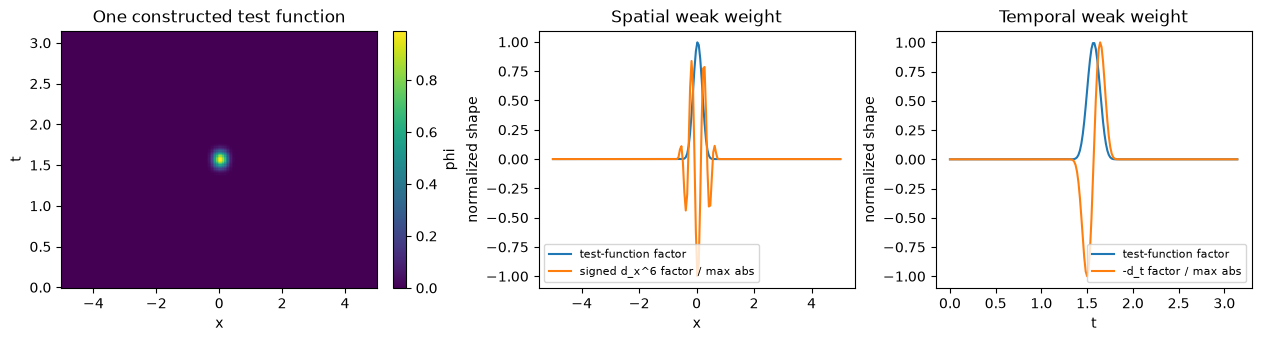

In [112]:
# 5b. Inspect the test functions that were actually constructed
gx, gt = [np.linspace(lo, hi, 200) for lo, hi in DOMAIN]
ix, it = [len(c) // 2 for c in phi.centers]
bx, bt = phi.basis(0, gx, 0)[ix], phi.basis(1, gt, 0)[it]
spatial_weight = phi.basis(0, gx, MAX_DX)[ix]
temporal_weight = phi.basis(1, gt, 1)[it]

fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.3), constrained_layout=True)
image = axes[0].pcolormesh(gx, gt, np.outer(bt, bx), shading='auto', cmap='viridis')
fig.colorbar(image, ax=axes[0], label='phi')
axes[0].set(xlabel='x', ylabel='t', title='One constructed test function')
for ax, grid, base, weight, label, title in (
    (axes[1], gx, bx, spatial_weight, f'signed d_x^{MAX_DX} factor / max abs', 'Spatial weak weight'),
    (axes[2], gt, bt, temporal_weight, '-d_t factor / max abs', 'Temporal weak weight'),
):
    peak = np.max(np.abs(weight))
    ax.plot(grid, base, label='test-function factor')
    ax.plot(grid, weight / peak if peak else weight, label=label)
    ax.set(xlabel='x' if ax is axes[1] else 't', ylabel='normalized shape', title=title)
    ax.legend(fontsize=8)
plt.show()

,matrix,min eigenvalue,max eigenvalue,negative eigenvalues (< -1e-10)
0,observed Gram (scaled),0.000002,43.516217,0
1,corrected Gamma (before projection),-7.513104,27.744962,100


K = 1804; P = 190; covariance shape = (190, 190)
LW uses the corrected matrix without PSD projection for final fitting.


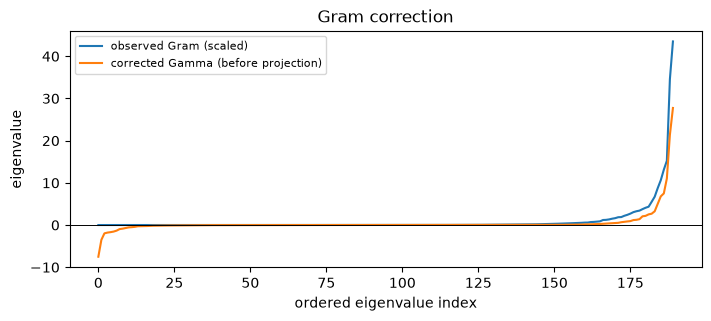

Fitting equation 0: d_t(u) with lw ...
Finished in 0.43 s; nonzero coefficients: 3
Fitting equation 1: d_t(v) with lw ...
Finished in 0.33 s; nonzero coefficients: 2
Total fitting time: 0.76 s


In [113]:
# 5c. Instantiate the selected estimator, inspect its moments, and fit
if METHOD not in {'coco', 'lw', 'mstls', 'least_squares'}:
    raise ValueError('METHOD must be coco, lw, mstls, or least_squares.')
if METHOD in {'coco', 'lw'}:
    lam_values = np.atleast_1d(np.asarray(LAM, dtype=float))
    if lam_values.size == 0 or np.any(lam_values < 0) or not np.all(np.isfinite(lam_values)):
        raise ValueError('LAM must contain finite, nonnegative penalties.')
    if np.ndim(LAM):
        if wf.data.design != 'random':
            raise ValueError('Corrected CV requires random integration points; use scalar LAM on a grid.')
        if int(FOLDS) != FOLDS or not 2 <= FOLDS <= wf.data.U.shape[-1]:
            raise ValueError('FOLDS must be an integer between 2 and the integration sample size.')
    for X, _ in systems:
        if np.any(np.linalg.norm(X, axis=0) == 0):
            raise ValueError('Zero-norm columns cannot be scaled by this repo estimator. '
                             'Inspect dictionary_table and the chosen test functions.')
    if METHOD == 'coco':
        estimator = CoCoLasso(LAM, folds=FOLDS, tol=SOLVER_TOL, max_iter=SOLVER_MAX_ITER)
    else:
        if not np.isfinite(LW_RADIUS) or LW_RADIUS <= 0:
            raise ValueError('LW_RADIUS must be finite and positive.')
        estimator = LohWainwright(LAM, LW_RADIUS, standardize=True, folds=FOLDS,
                                 tol=SOLVER_TOL, max_iter=SOLVER_MAX_ITER)
else:
    if METHOD == 'mstls' and (np.any(np.asarray(MSTLS_LAMBDAS) <= 0)
                              or not np.all(np.isfinite(MSTLS_LAMBDAS))):
        raise ValueError('MSTLS thresholds must be finite and positive.')
    estimator = WSINDy('mstls' if METHOD == 'mstls' else 'fixed', lambdas=MSTLS_LAMBDAS)

# The two NLS equations share the same RHS and test functions, hence the same X and Gamma.
gram_diagnostics = None
if SHOW_GRAM_DIAGNOSTICS and METHOD in {'coco', 'lw'}:
    X, _ = systems[0]
    scale = np.sqrt(np.mean(X**2, axis=0)) if estimator.standardize else np.ones(X.shape[1])
    Sigma_W = wf.noise_covariance(equations[0])
    observed_gram = (X / scale).T @ (X / scale) / K
    scaled_covariance = Sigma_W / np.outer(scale, scale)
    Gamma = observed_gram - scaled_covariance
    eigenvalues = {
        'observed Gram (scaled)': np.linalg.eigvalsh(observed_gram),
        'corrected Gamma (before projection)': np.linalg.eigvalsh(Gamma),
    }
    gram_diagnostics = pd.DataFrame([
        {'matrix': name, 'min eigenvalue': values.min(), 'max eigenvalue': values.max(),
         'negative eigenvalues (< -1e-10)': int(np.sum(values < -1e-10))}
        for name, values in eigenvalues.items()
    ])
    display(gram_diagnostics)
    print(f'K = {K}; P = {len(rhs)}; covariance shape = {Sigma_W.shape}')
    print('CoCoLasso applies the repo ADMM projection to A >= 1e-3 I inside estimate().'
          if METHOD == 'coco' else 'LW uses the corrected matrix without PSD projection for final fitting.')
    fig, ax = plt.subplots(figsize=(7, 3.1), constrained_layout=True)
    for name, values in eigenvalues.items():
        ax.plot(values, label=name)
    ax.axhline(0, color='black', linewidth=0.7)
    ax.set(xlabel='ordered eigenvalue index', ylabel='eigenvalue', title='Gram correction')
    ax.legend(fontsize=8)
    plt.show()
else:
    print('Corrected-Gram diagnostics are off or not used by this method.')

betas, elapsed, solver_warnings = [], [], []
for q, equation in enumerate(equations):
    print(f'Fitting equation {q}: {term_text(equation.lhs)} with {METHOD} ...', flush=True)
    started = perf_counter()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        beta = estimator.estimate(wf, equation)
    elapsed.append(perf_counter() - started)
    betas.append(beta)
    messages = list(dict.fromkeys(str(w.message) for w in caught))
    solver_warnings.append(messages)
    print(f'Finished in {elapsed[-1]:.2f} s; nonzero coefficients: {np.count_nonzero(beta)}', flush=True)
    for message in messages:
        print(f'  Solver warning: {message}')
    if not np.all(np.isfinite(beta)):
        raise RuntimeError('The estimator returned nonfinite coefficients; inspect the settings/system above.')
print(f'Total fitting time: {sum(elapsed):.2f} s')

## 6. Compare coefficients and visualize the results

Map the known coefficients onto the chosen dictionary for evaluation, display both equations,
and inspect coefficient errors and support recovery. Exact nonzero coefficients define support, as in `report.py`.
If the chosen dictionary omits true terms, the coefficient metrics apply only to its columns.
The weak residual is an in-sample diagnostic. No repeated-instance mean or standard deviation is computed.

In [114]:
# Map truth only for evaluation, after fitting
EQUATION_TERMS = 12
PLOT_TERMS = 15

beta_stars = [np.array([dict(zip(true_eq.rhs, star)).get(term, 0.0) for term in eq.rhs])
              for eq, true_eq, star in zip(equations, pde.equations, pde.beta_star)]
missing_terms = [[term_text(t) for t in true_eq.rhs if t not in eq.rhs]
                 for eq, true_eq in zip(equations, pde.equations)]
for q, absent in enumerate(missing_terms):
    if absent:
        print(f'Equation {q}: true terms outside the dictionary: {absent}. '
              'Coefficient metrics apply only to the chosen dictionary.')

coefficient_tables = []
for q, (equation, beta, star) in enumerate(zip(equations, betas, beta_stars)):
    show_equation(equation.lhs, pde.equations[q].rhs, pde.beta_star[q], f'Equation {q}: true PDE')
    show_equation(equation.lhs, equation.rhs, beta, f'Equation {q}: estimated PDE', limit=EQUATION_TERMS)
    table = pd.DataFrame({
        'column': np.arange(len(rhs)), 'term': [term_text(t) for t in rhs],
        'beta_true': star, 'beta_hat': beta, 'error': beta - star,
        'true_support': star != 0, 'selected': beta != 0,
    })
    coefficient_tables.append(table)
    if SHOW_FULL_DICTIONARY:
        visible = table
    else:
        visible = table[table.true_support | table.selected].copy()
        visible['abs_beta_hat'] = np.abs(visible.beta_hat)
        visible = visible.sort_values(['true_support', 'abs_beta_hat'], ascending=False)
        print(f'Showing up to {TABLE_ROWS} true or selected terms; full coefficients: coefficient_tables[{q}].')
        visible = visible.drop(columns='abs_beta_hat').head(TABLE_ROWS)
    display(visible)

**Equation 0: true PDE**

<IPython.core.display.Latex object>

**Equation 0: estimated PDE**

<IPython.core.display.Latex object>

Showing up to 25 true or selected terms; full coefficients: coefficient_tables[0].


,column,term,beta_true,beta_hat,error,true_support,selected
6,6,v^3,1.0,0.755365,-0.244635,True,True
8,8,u^2 v,1.0,0.123996,-0.876004,True,True
55,55,d_x^2(v),0.5,0.000000,-0.500000,True,False
1,1,v,0.0,0.459054,0.459054,False,True


... (2 outputs left out)

**Equation 1: estimated PDE**

<IPython.core.display.Latex object>

Showing up to 25 true or selected terms; full coefficients: coefficient_tables[1].


,column,term,beta_true,beta_hat,error,true_support,selected
9,9,u^3,-1.0,-0.548823,0.451177,True,True
7,7,u v^2,-1.0,-0.000000,1.000000,True,False
56,56,d_x^2(u),-0.5,-0.000000,0.500000,True,False
2,2,u,0.0,-0.010992,-0.010992,False,True


,L2 error,relative L2 error,TP,FP,FN,precision,recall,F1,relative weak residual,fit seconds,solver warnings
equation,,,,,,,,,,,
0,1.134883,0.756589,2,1,1,0.666667,0.666667,0.666667,0.720029,0.433623,0
1,1.205687,0.803791,1,1,2,0.500000,0.333333,0.400000,0.705836,0.325564,0
combined,1.655790,0.780547,3,2,3,0.600000,0.500000,0.545455,0.714405,0.759186,0


Support uses exact nonzero coefficients, as report.py does. Weak residual is an in-sample diagnostic; it is not a held-out prediction error.


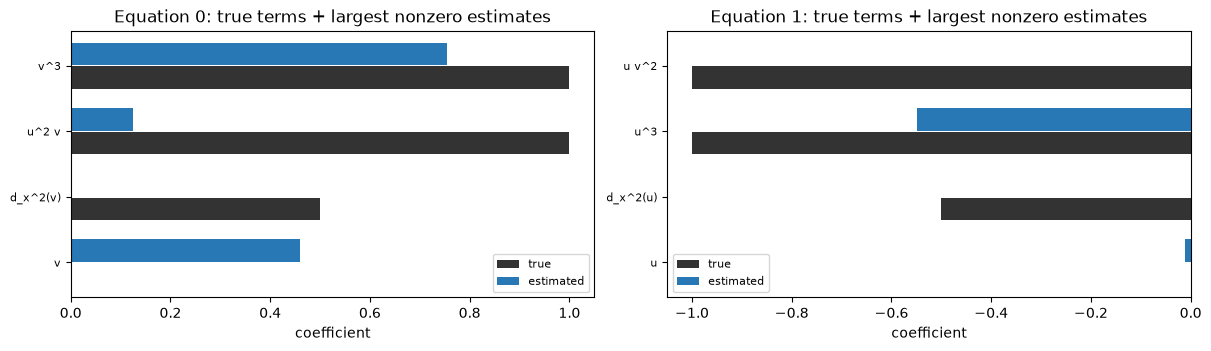

In [115]:
# Single-instance evaluation and coefficient plots
def coefficient_metrics(beta, star):
    selected, actual = beta != 0, star != 0
    tp = int(np.sum(selected & actual))
    fp = int(np.sum(selected & ~actual))
    fn = int(np.sum(~selected & actual))
    norm = np.linalg.norm(star)
    return {
        'L2 error': np.linalg.norm(beta - star),
        'relative L2 error': np.linalg.norm(beta - star) / norm if norm else np.nan,
        'TP': tp, 'FP': fp, 'FN': fn,
        'precision': tp / (tp + fp) if tp + fp else 0.0,
        'recall': tp / (tp + fn) if tp + fn else 0.0,
        'F1': 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0.0,
    }


metric_rows = []
residuals, responses = [], []
for q, ((X, Y), beta, star) in enumerate(zip(systems, betas, beta_stars)):
    residual = Y - X @ beta
    residuals.append(residual)
    responses.append(Y)
    metric_rows.append({
        'equation': q, **coefficient_metrics(beta, star),
        'relative weak residual': np.linalg.norm(residual) / np.linalg.norm(Y) if np.linalg.norm(Y) else np.nan,
        'fit seconds': elapsed[q], 'solver warnings': len(solver_warnings[q]),
    })
all_beta, all_star = np.concatenate(betas), np.concatenate(beta_stars)
metric_rows.append({
    'equation': 'combined', **coefficient_metrics(all_beta, all_star),
    'relative weak residual': np.linalg.norm(np.concatenate(residuals)) / np.linalg.norm(np.concatenate(responses)),
    'fit seconds': sum(elapsed), 'solver warnings': sum(map(len, solver_warnings)),
})
metrics_table = pd.DataFrame(metric_rows).set_index('equation')
display(metrics_table)
print('Support uses exact nonzero coefficients, as report.py does. '
      'Weak residual is an in-sample diagnostic; it is not a held-out prediction error.')

shown_rows = max(min(PLOT_TERMS, np.count_nonzero((beta != 0) | (star != 0)))
                 for beta, star in zip(betas, beta_stars))
fig, axes = plt.subplots(1, 2, figsize=(12, max(3.4, 0.4 * shown_rows + 1.4)), constrained_layout=True)
for q, (ax, beta, star) in enumerate(zip(axes, betas, beta_stars)):
    true_ids = np.flatnonzero(star != 0)
    other_ids = np.array([i for i in np.argsort(-np.abs(beta))
                          if beta[i] != 0 and i not in set(true_ids)], dtype=int)
    ids = np.concatenate([true_ids, other_ids[:max(0, PLOT_TERMS - len(true_ids))]])
    ids = ids[::-1]
    y = np.arange(len(ids))
    ax.barh(y - 0.18, star[ids], height=0.34, label='true', color='#333333')
    ax.barh(y + 0.18, beta[ids], height=0.34, label='estimated', color='#2878b5')
    ax.set_yticks(y, [term_text(rhs[i]) for i in ids], fontsize=8)
    ax.axvline(0, color='black', linewidth=0.6)
    ax.set(xlabel='coefficient', title=f'Equation {q}: true terms + largest nonzero estimates')
    ax.legend(fontsize=8)
plt.show()